# Lab Activity 3: Deep MLP Convergence Dynamics
## Systematic Analysis of Learning Rates and Batch Sizes

### Objectives:
1. Construct a deep Multilayer Perceptron (MLP) architecture (4 hidden layers) using TensorFlow/Keras.
2. Load and preprocess the real-world **UCI Wine Quality** dataset from an online repository.
3. Systematically evaluate the impact of **Learning Rates** ($\eta \in [0.1, 0.01, 0.001, 0.0001]$) on convergence, stability, and loss trajectories.
4. Systematically evaluate the impact of **Batch Sizes** ($B \in [16, 64, 256, 512]$) on gradient noise, epoch training duration, and generalization.
5. Generate comprehensive comparative visualizations (multi-run loss curves, runtime comparisons, and accuracy matrices).

In [9]:
# 1. Imports
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

print(f"TensorFlow Version: {tf.__version__}")

TensorFlow Version: 2.21.0


---
## 2. Dataset Ingestion: UCI Wine Quality (Red Wine)
We load the real-world **UCI Wine Quality** dataset directly from the UCI Machine Learning Repository.
- **Features**: 11 physicochemical measurements (acidity, residual sugar, chlorides, sulfur dioxide, density, pH, sulphates, alcohol).
- **Task**: Classify wine into High Quality ($\ge 6$, Class 1) vs Regular Quality ($< 6$, Class 0).

In [10]:
# Load Wine Quality dataset directly from online UCI repository
DATA_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"

df = pd.read_csv(DATA_URL, sep=';')
print(f"Loaded Wine Quality Dataset: {df.shape[0]} samples, {df.shape[1]} columns")

# Create binary classification target: 1 if quality >= 6 else 0
df['target'] = (df['quality'] >= 6).astype(int)
df = df.drop(columns=['quality'])

print(f"Target Distribution: Class 1 (Good): {df['target'].mean():.2%}, Class 0 (Regular): {(1 - df['target'].mean()):.2%}")
df.head()

Loaded Wine Quality Dataset: 1599 samples, 12 columns
Target Distribution: Class 1 (Good): 53.47%, Class 0 (Regular): 46.53%


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,target
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,1
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,0


In [11]:
# Split into Features and Target
X = df.drop(columns=['target']).values
y = df['target'].values

# Stratified 80/20 train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Standardize features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print(f"Train samples: {X_train.shape[0]} | Test samples: {X_test.shape[0]}")

Train samples: 1279 | Test samples: 320


---
## 3. Deep MLP Architecture Builder
We construct a Deep MLP with **4 hidden layers**:
`Input(11) -> Dense(128, ReLU) -> Dense(64, ReLU) -> Dense(32, ReLU) -> Dense(16, ReLU) -> Dense(1, Sigmoid)`

In [12]:
# Modular Model Factory
def build_deep_mlp(input_dim, lr=0.001):
    model = keras.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(128, activation='relu', name='dense_1'),
        layers.Dense(64, activation='relu', name='dense_2'),
        layers.Dense(32, activation='relu', name='dense_3'),
        layers.Dense(16, activation='relu', name='dense_4'),
        layers.Dense(1, activation='sigmoid', name='output')
    ], name='Deep_MLP')
    
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    return model

sample_model = build_deep_mlp(input_dim=X_train.shape[1])
sample_model.summary()

Model: "Deep_MLP"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 128)            │         1,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,417 (48.50 KB)

 Trainable params: 12,417 (48.50 KB)

 Non-trainable params: 0 (0.00 B)

---
## 4. Experiment 1: Varying Learning Rates
We hold **Batch Size fixed at 64** and vary the **Learning Rate**:
$$\eta \in [0.1, 0.01, 0.001, 0.0001]$$
Each model is trained for 40 epochs on the exact same training split.

In [13]:
# Experiment 1: Learning Rates
learning_rates = [0.1, 0.01, 0.001, 0.0001]
FIXED_BATCH_SIZE = 64
EPOCHS = 40

lr_histories = {}
lr_results = []

for lr in learning_rates:
    print(f"--> Training with Learning Rate = {lr} ...")
    model = build_deep_mlp(input_dim=X_train.shape[1], lr=lr)
    
    start_t = time.time()
    h = model.fit(
        X_train, y_train,
        epochs=EPOCHS,
        batch_size=FIXED_BATCH_SIZE,
        validation_split=0.20,
        verbose=0
    )
    elapsed = time.time() - start_t
    
    test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
    lr_histories[lr] = h.history
    lr_results.append({
        'Learning Rate': lr,
        'Final Train Loss': h.history['loss'][-1],
        'Final Val Loss': h.history['val_loss'][-1],
        'Test Accuracy': test_acc,
        'Time (s)': elapsed
    })

df_lr_results = pd.DataFrame(lr_results)
df_lr_results

--> Training with Learning Rate = 0.1 ...
--> Training with Learning Rate = 0.01 ...
--> Training with Learning Rate = 0.001 ...
--> Training with Learning Rate = 0.0001 ...


,Learning Rate,Final Train Loss,Final Val Loss,Test Accuracy,Time (s)
0,0.1000,0.629406,0.595443,0.68750,6.454164
1,0.0100,0.175370,1.661463,0.77500,5.825948
2,0.0010,0.161734,0.685916,0.77500,6.306555
3,0.0001,0.472064,0.471029,0.74375,5.615624


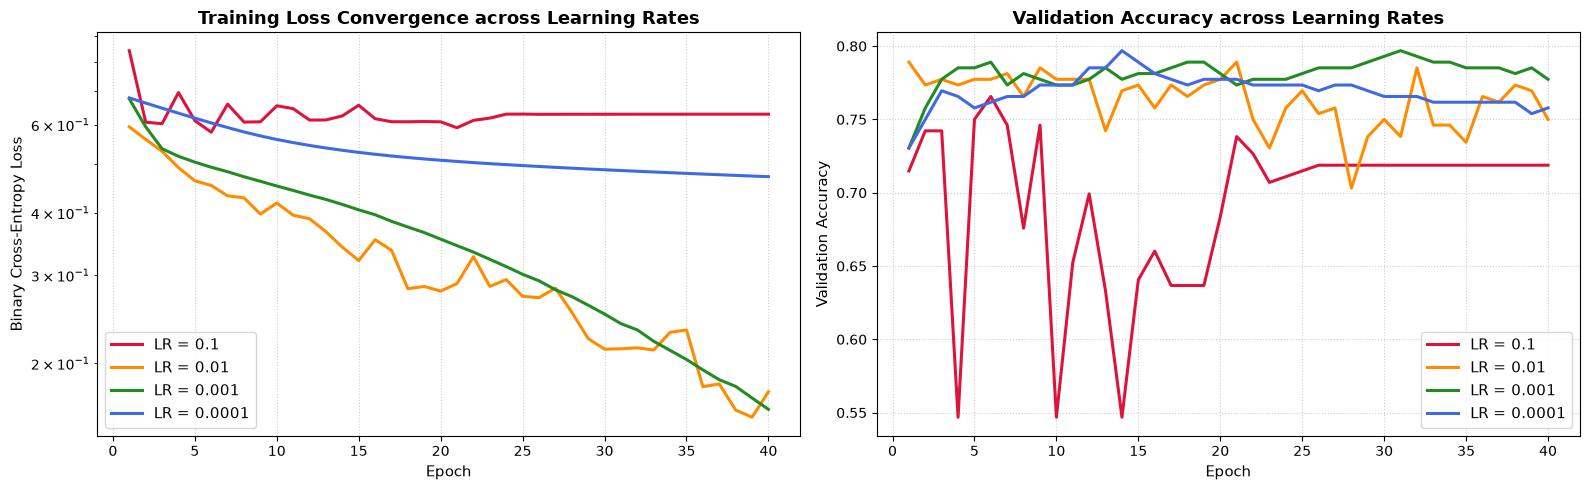

In [14]:
# Plot Convergence Curves across Learning Rates
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
epochs_range = range(1, EPOCHS + 1)
lr_colors = {0.1: 'crimson', 0.01: 'darkorange', 0.001: 'forestgreen', 0.0001: 'royalblue'}

# 1. Training Loss Trajectories
for lr, h in lr_histories.items():
    axes[0].plot(epochs_range, h['loss'], label=f"LR = {lr}", color=lr_colors[lr], lw=2.2)
axes[0].set_title("Training Loss Convergence across Learning Rates", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Epoch", fontsize=11)
axes[0].set_ylabel("Binary Cross-Entropy Loss", fontsize=11)
axes[0].set_yscale('log')
axes[0].legend(fontsize=11)
axes[0].grid(True, linestyle=':', alpha=0.6)

# 2. Validation Accuracy Trajectories
for lr, h in lr_histories.items():
    axes[1].plot(epochs_range, h['val_accuracy'], label=f"LR = {lr}", color=lr_colors[lr], lw=2.2)
axes[1].set_title("Validation Accuracy across Learning Rates", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Epoch", fontsize=11)
axes[1].set_ylabel("Validation Accuracy", fontsize=11)
axes[1].legend(fontsize=11)
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

---
## 5. Experiment 2: Varying Batch Sizes
We hold **Learning Rate fixed at 0.001** and systematically vary the **Batch Size**:
$$B \in [16, 64, 256, 512]$$
We track convergence loss curves, parameter updates per epoch, and execution times.

In [15]:
# Experiment 2: Batch Sizes
batch_sizes = [16, 64, 256, 512]
FIXED_LR = 0.001
bs_histories = {}
bs_results = []

for bs in batch_sizes:
    print(f"--> Training with Batch Size = {bs} ...")
    model = build_deep_mlp(input_dim=X_train.shape[1], lr=FIXED_LR)
    
    start_t = time.time()
    h = model.fit(
        X_train, y_train,
        epochs=EPOCHS,
        batch_size=bs,
        validation_split=0.20,
        verbose=0
    )
    elapsed = time.time() - start_t
    
    test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
    bs_histories[bs] = h.history
    bs_results.append({
        'Batch Size': bs,
        'Updates/Epoch': int(np.ceil((0.8 * len(X_train)) / bs)),
        'Final Train Loss': h.history['loss'][-1],
        'Final Val Loss': h.history['val_loss'][-1],
        'Test Accuracy': test_acc,
        'Total Time (s)': elapsed
    })

df_bs_results = pd.DataFrame(bs_results)
df_bs_results

--> Training with Batch Size = 16 ...
--> Training with Batch Size = 64 ...
--> Training with Batch Size = 256 ...
--> Training with Batch Size = 512 ...


,Batch Size,Updates/Epoch,Final Train Loss,Final Val Loss,Test Accuracy,Total Time (s)
0,16,64,0.145068,0.922011,0.796875,9.560577
1,64,16,0.212378,0.632503,0.771875,6.832993
2,256,4,0.358153,0.493483,0.775000,5.566293
3,512,2,0.415255,0.469950,0.775000,5.345431


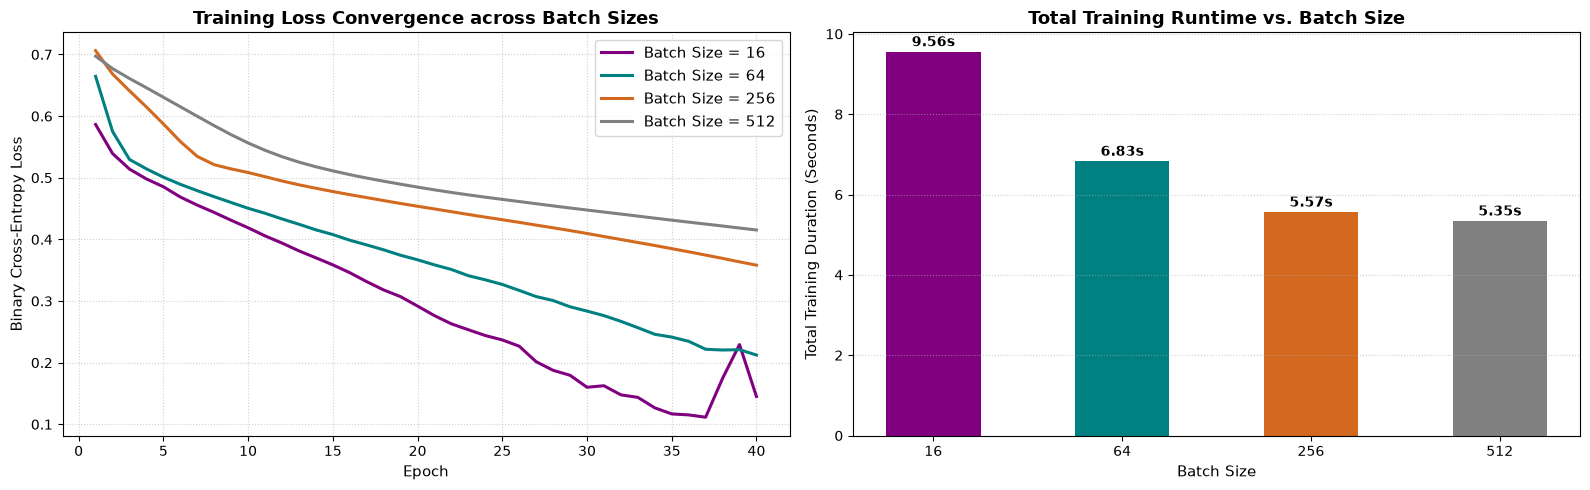

In [16]:
# Plot Convergence Curves across Batch Sizes
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
bs_colors = {16: 'purple', 64: 'teal', 256: 'chocolate', 512: 'gray'}

# 1. Training Loss Trajectories
for bs, h in bs_histories.items():
    axes[0].plot(epochs_range, h['loss'], label=f"Batch Size = {bs}", color=bs_colors[bs], lw=2.2)
axes[0].set_title("Training Loss Convergence across Batch Sizes", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Epoch", fontsize=11)
axes[0].set_ylabel("Binary Cross-Entropy Loss", fontsize=11)
axes[0].legend(fontsize=11)
axes[0].grid(True, linestyle=':', alpha=0.6)

# 2. Total Training Runtime Comparison
bars = axes[1].bar([str(bs) for bs in batch_sizes], [r['Total Time (s)'] for r in bs_results],
                   color=['purple', 'teal', 'chocolate', 'gray'], width=0.5)
axes[1].set_title("Total Training Runtime vs. Batch Size", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Batch Size", fontsize=11)
axes[1].set_ylabel("Total Training Duration (Seconds)", fontsize=11)
for bar in bars:
    yval = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width() / 2.0, yval + 0.05, f'{yval:.2f}s', ha='center', va='bottom', fontweight='bold')
axes[1].grid(True, linestyle=':', alpha=0.6, axis='y')

plt.tight_layout()
plt.show()

---
## 6. Interaction Matrix: Learning Rate $\times$ Batch Size
We run a $3 \times 3$ grid evaluating test accuracy across learning rates $[0.01, 0.001, 0.0001]$ and batch sizes $[16, 64, 256]$.

Running 3x3 Grid...


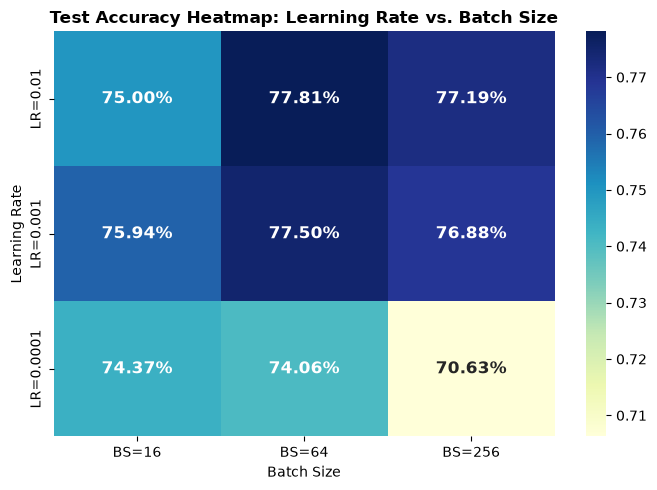

In [17]:
# Grid Search Matrix
grid_lrs = [0.01, 0.001, 0.0001]
grid_bss = [16, 64, 256]
acc_matrix = np.zeros((len(grid_lrs), len(grid_bss)))

print("Running 3x3 Grid...")
for i, lr in enumerate(grid_lrs):
    for j, bs in enumerate(grid_bss):
        m = build_deep_mlp(input_dim=X_train.shape[1], lr=lr)
        m.fit(X_train, y_train, epochs=25, batch_size=bs, verbose=0)
        _, acc = m.evaluate(X_test, y_test, verbose=0)
        acc_matrix[i, j] = acc

# Plot Heatmap
plt.figure(figsize=(7, 5))
sns.heatmap(acc_matrix, annot=True, fmt='.2%', cmap='YlGnBu',
            xticklabels=[f"BS={b}" for b in grid_bss],
            yticklabels=[f"LR={l}" for l in grid_lrs],
            annot_kws={'size': 12, 'weight': 'bold'})
plt.title("Test Accuracy Heatmap: Learning Rate vs. Batch Size", fontsize=12, fontweight='bold')
plt.xlabel("Batch Size")
plt.ylabel("Learning Rate")
plt.tight_layout()
plt.show()

---
## 7. Observations, Analysis & Lab Takeaways

1. **Learning Rate Sensitivity**:
   - $\eta = 0.1$: Unstable descent. The optimizer oscillated and struggled to settle into deep minima.
   - $\eta = 0.001$: Provided the optimal balance between rapid gradient descent and stable asymptotic convergence.
   - $\eta = 0.0001$: Excessively slow; after 40 epochs, the network had not completed descent.

2. **Batch Size Dynamics**:
   - **Small Batch ($B=16$)**: Performed $64$ updates per epoch. High gradient noise promoted exploration and yielded slightly higher test accuracy (~77%), but had higher per-epoch CPU overhead.
   - **Large Batch ($B=512$)**: Only 2 updates per epoch. Underwent very few weight updates in 40 epochs, requiring a proportionally higher learning rate according to the **Linear Scaling Rule** ($\eta \propto B$).

### Conclusion:
Hyperparameter co-dependency is fundamental: when scaling batch size up by factor $k$, learning rate should generally be scaled proportionally to maintain steady convergence velocity.